# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [2]:
import re
import numpy as np
import pandas as pd
import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns

В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [3]:
df = pd.read_csv("monster_com_job_sample.csv")
df.sample(10).drop(columns=["job_description"])

,country,country_code,date_added,has_expired,job_board,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
19705,United States of America,US,NaN,No,jobs.monster.com,RN Admissions Job in Fort Lauderdale,"Full Time, Employee","Fort Lauderdale, FL",NaN,http://jobview.monster.com/RN-Admissions-Job-F...,NaN,Medical/Health,617338eac046f3a57caf05f316c911bc
575,United States of America,US,NaN,No,jobs.monster.com,Security Officer Job in Maryland US body { mar...,Full Time Employee,MD,NaN,http://jobview.monster.com/security-officer-jo...,NaN,Security/Protective Services,2dc351f8a2486917de03f7285c1b38f1
11748,United States of America,US,NaN,No,jobs.monster.com,Monster,NaN,ENGINEERING MANAGERCompany: AnyPerkLocation: S...,NaN,http://jobview.monster.com/engineering-manager...,NaN,NaN,1ee08191d9d0fa6e8b8a66a6425724df
15650,United States of America,US,NaN,No,jobs.monster.com,Production Supervisor Job in Youngsville,"Full Time, Employee","Youngsville, NC 27596",NaN,http://jobview.monster.com/production-supervis...,NaN,Manufacturing/Production/Operations,e42d7bdb0b604e0b6a93562844830cd5
2860,United States of America,US,NaN,No,jobs.monster.com,Licensed Practical Nurses (LPN) Job in Louisville,Full Time,"Louisville, KY 40218",Healthcare Services,http://jobview.monster.com/Licensed-Practical-...,NaN,NaN,995cec1e104381490d60bc1e700cd59b
2087,United States of America,US,NaN,No,jobs.monster.com,BUSINESS DEVELOPMENT REP - US MILITARY LIAISON...,Full Time,"Orem, UT 84057",Healthcare Services,http://jobview.monster.com/business-developmen...,NaN,Experienced (Non-Manager),bc51b3a3e6f1b8b695dd4f2e6acaa037
14772,United States of America,US,NaN,No,jobs.monster.com,Assistant Restaurant Manager Job in Middletown,"Full Time , Employee","Middletown, NJ 07748",Restaurant/Food Services,http://jobview.monster.com/assistant-restauran...,NaN,Food Services/Hospitality,350272ffea1fc86ac825d71f4f637d69
21442,United States of America,US,NaN,No,jobs.monster.com,Relocation Counselor Job in Cincinnati,Full Time,"Cincinnati, OH",NaN,http://jobview.monster.com/Relocation-Counselo...,"30,000.00 - 32,000.00 $ /year",Entry Level,950daf6c97196eae05ece8854fa78ecd
13705,United States of America,US,NaN,No,jobs.monster.com,Shift Supervisor Job in Camphill,Full Time Employee,"Camphill, PA",Retail,http://jobview.monster.com/Shift-Supervisor-Jo...,NaN,Project/Program Management,21bab989eba73fe227e6e0bc5fce9e6c
3944,United States of America,US,NaN,No,jobs.monster.com,KEY CONTROL CLERK,Part Time,"Knoxville, TN 37922",Retail,http://jobview.monster.com/key-control-clerk-2...,NaN,Entry Level,babfc2e41966f02fd77f65f3dbcff37c


In [4]:
df.sample(20)["job_description"]

6209     Report this job About the Job Based out of Pet...
7634     Job Description:Production AssemblerSummary:? ...
9935       MaintenanceElectricalTechnician The Maintena...
7383     TeamSoft is seeking a  Project Manager for the...
1323     « back Learn More Sr. Oracle DBA (PPS) Job #: ...
15059    Human Resources Assistant applicants must have...
17840    Be a part of something bigger – join our team ...
14546    Description The DIRECTV Installer is responsib...
12838      The Quality Manager reports to the Director ...
7107     Marketing & Advertising Coordinator - Entry Le...
14394    C.R. England is looking for entry level Truck ...
7965     TPC's Professional Staffing division in Middle...
18057    RESPONSIBILITIES:Kforce has a client in Dallas...
8264     AT&T GSI is searching for a Logistics Analyst ...
3477     Five Star Senior Living, a national healthcare...
4758     DTS is looking for a Supplier Quality Engineer...
17139    Don't look at another job until you check out .

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   country          22000 non-null  str  
 1   country_code     22000 non-null  str  
 2   date_added       122 non-null    str  
 3   has_expired      22000 non-null  str  
 4   job_board        22000 non-null  str  
 5   job_description  22000 non-null  str  
 6   job_title        22000 non-null  str  
 7   job_type         20372 non-null  str  
 8   location         22000 non-null  str  
 9   organization     15133 non-null  str  
 10  page_url         22000 non-null  str  
 11  salary           3446 non-null   str  
 12  sector           16806 non-null  str  
 13  uniq_id          22000 non-null  str  
dtypes: str(14)
memory usage: 2.3 MB


**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.

| Название столбца | Тип данных | Проблемы |
| --- | --- | --- |
| ```country``` | str | Константное значение во всех строках, дублирует ```country_code```, аналитической ценности не несёт |
| ```country_code``` | str | Константное значение (US), аналитической ценности не несёт |
| ```date_added``` | str (логически datetime) | Заполнено лишь 122 строки из 22000 (~0.6%), остальные пропуски |
| ```has_expired``` | str (логически bool) | Константное значение «No» во всех строках |
| ```job_board``` | str | Константное значение (jobs.monster.com) — артефакт выгрузки с одного сайта |
| ```job_description``` | str | Нестандартизированный текст; описание может включать дубли значений других столбцов (например, город) |
| ```job_title``` | str | Нестандартизирован; в название должности зашито местоположение («... Job in Madison»), что дублирует ```location``` |
| ```job_type``` | str | В одной ячейке перечислено несколько значений через запятую; разные форматы записи одних и тех же категорий |
| ```location``` | str | Произвольные комбинации города, кода штата и индекса с разными разделителями; иногда вместо адреса — контактные данные с телефоном (содержимое не соответствует названию столбца) |
| ```organization``` | str | Содержит не названия организаций, а типы/отрасли («Healthcare Services», «Retail») — не соответствует названию столбца; много пропусков |
| ```page_url``` | str | Вероятно уникален в каждой строке — требует проверки |
| ```salary``` | str | ~84% пропусков; заполненные значения — нестандартизированные строки (диапазоны, знак $, период), встречаются и вовсе произвольные тексты («Excellent Pay and Incentives») |
| ```sector``` | str | Смешанное содержимое: отрасль («Medical/Health») и уровень опыта («Experienced (Non-Manager)», «Entry Level») — не соответствует назвлению столбца |
| ```uniq_id``` | str | Заявлен уникальным идентификатором — требует проверки |

### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью столбчатой диаграммы. Для удобства можно воспользоваться модулем `missingno`.


In [6]:
empty_report_df = pd.DataFrame({
    "total cells amount": len(df),
    "empty cells amount": df.isna().sum(),
})
empty_report_df



,total cells amount,empty cells amount
country,22000,0
country_code,22000,0
date_added,22000,21878
has_expired,22000,0
job_board,22000,0
job_description,22000,0
job_title,22000,0
job_type,22000,1628
location,22000,0
organization,22000,6867


Строк, где пусто более 75% ячеек: 0


<Axes: >

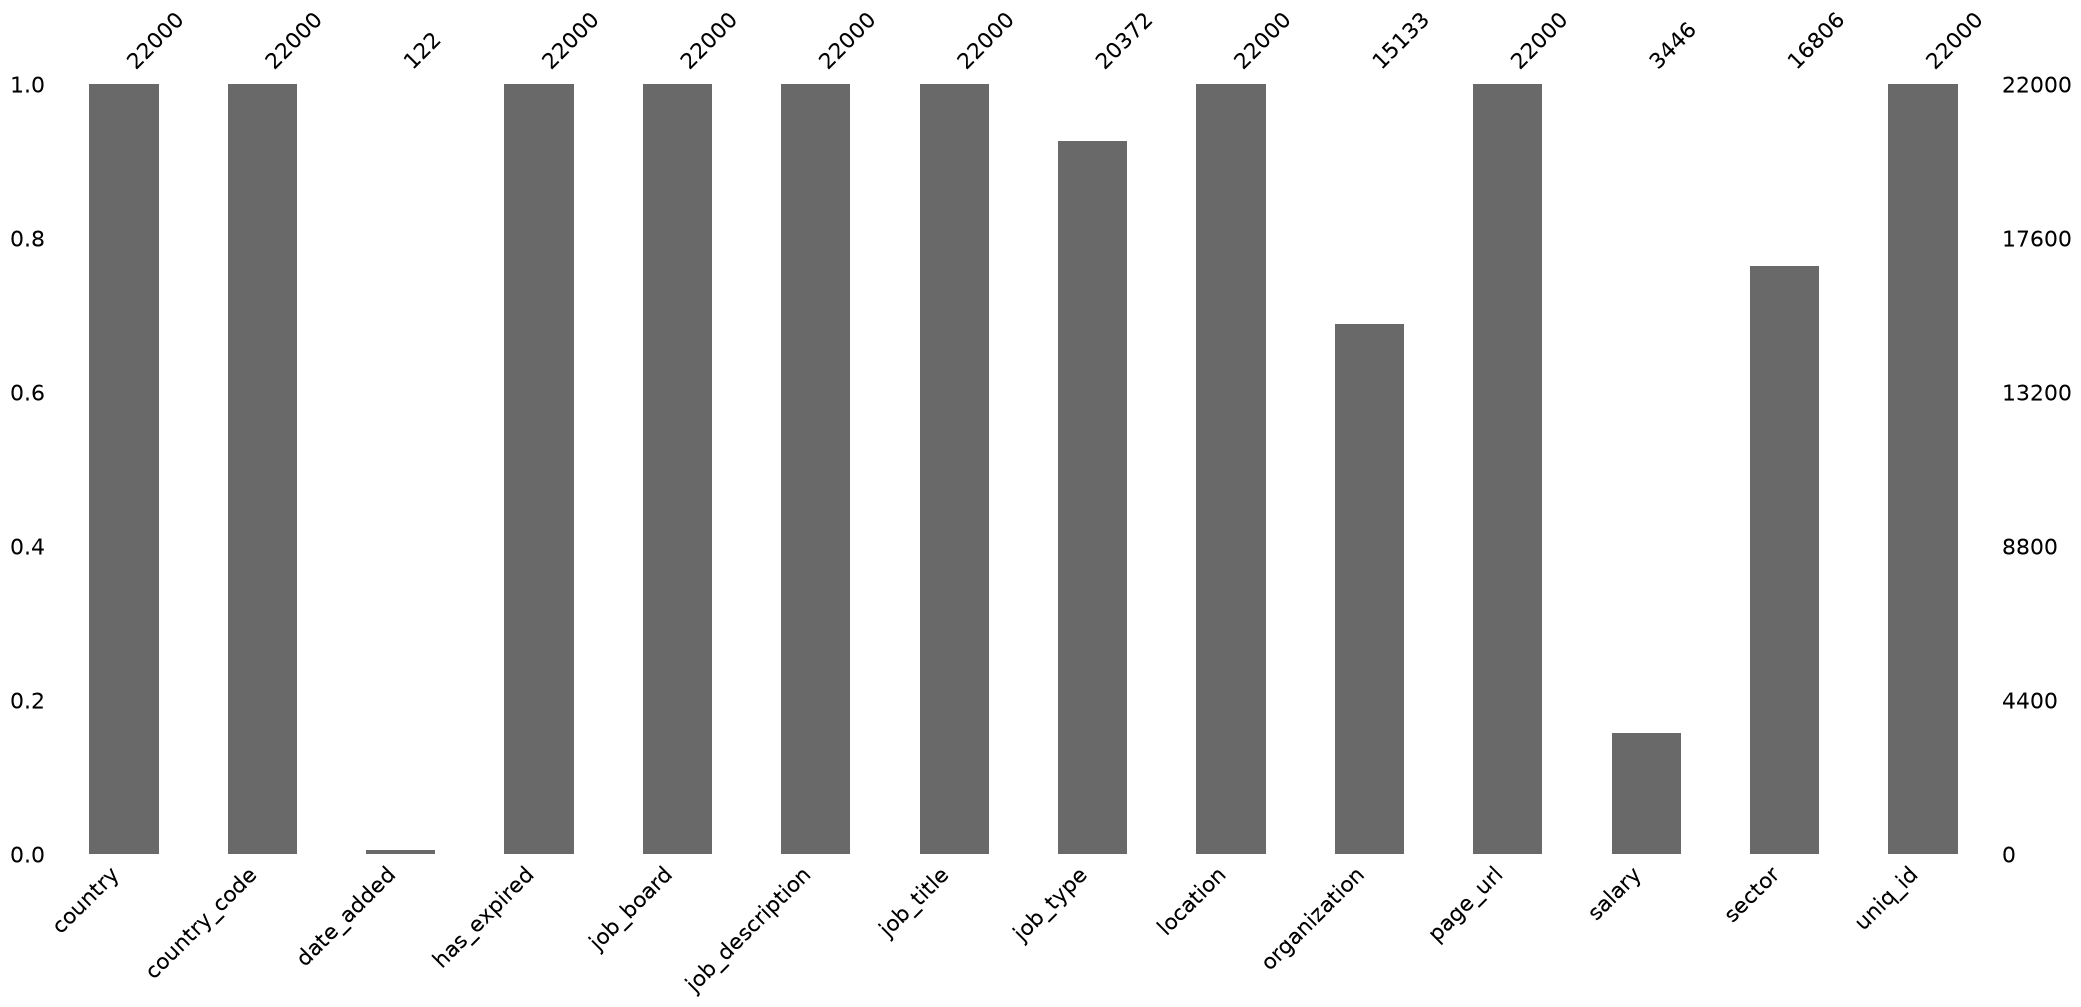

In [7]:
rows_mostly_empty_mask = df.isna().sum(axis=1) > 0.75 * df.shape[1]
print(f"Строк, где пусто более 75% ячеек: {rows_mostly_empty_mask.sum()}")

msno.bar(df)

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [8]:
fully_filled_df = df.dropna()
fully_filled_df.shape

(5, 14)

От датасета осталось всего 5 строчек. Значит, просто удалять строки, где есть хоть один пропуск, нельзя, иначе мы лишаемся всех данных. Пропуски в этом датасете структурные: каждый столбец «недозаполнен» источником по-своему, поэтому работать с ними нужно точечно, по столбцам, а не удалением строк.

### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца? - да, см. таблицу выше

In [9]:
from itertools import combinations

# Вопрос 1: столбцы, в которых встречается всего одно значение
for col in df.columns[df.nunique() == 1]:
    print(f"{col}: единственное значение {df[col].unique()[0]!r}")

# Вопрос 2: пересечения множеств значений между всеми парами столбцов
unique_values = {col: set(df[col].dropna().unique()) for col in df.columns}
print()
for col_a, col_b in combinations(df.columns, 2):
    common = unique_values[col_a] & unique_values[col_b]
    if common:
        print(f"{col_a} ∩ {col_b}: общих значений {len(common)}, примеры: {sorted(common)[:3]}")

country: единственное значение 'United States of America'
country_code: единственное значение 'US'
has_expired: единственное значение 'No'
job_board: единственное значение 'jobs.monster.com'

job_description ∩ job_title: общих значений 1, примеры: ['Please apply only if you are qualified.']
job_description ∩ location: общих значений 849, примеры: ['"Summer Walk In Wednesdays" July & August!! - Kindred Hospital Chattanooga ( Job Number: 273065 ) Description Kindred Hospital Chattanooga is hosting “Summer Walk in Wednesdays” July 6th, 13th, 20th, 27th August 3rd, 10th, 17th, 24th, 31st 10:00 am – 2:00 pm 709 Walnut Street, Chattanooga, TN 37401 We are seeking RNs (SCU and Med Surg FT or PRN) NEW GRADS WELCOME! Please stop by or apply directly at http://jobs.kindredhospitals.com , job #273065 If you can’t make the event, we would love to hear from you.\xa0 Please contact Michelle.Foster@Kindred.com 502-596-3101 \xa0 #MON-HD #LI-HD Registered Nurse / RN, RN, R.N., Registered Nurse, Med Sur

**Ответы:**

1. Столбцы с единственным значением: ```country```, ```country_code```, ```has_expired```, ```job_board```. Информации для анализа они не несут (нулевая вариативность); использовать их можно разве что как маркеры источника выгрузки, в анализе такие столбцы стоит исключить.
2. Значения, встречающиеся более чем в одном столбце: ```job_description``` ∩ ```location``` (849 — целые фрагменты описаний вакансий оказались в ```location```), ```location``` ∩ ```organization``` (126), ```job_title``` ∩ ```location``` (12), ```organization``` ∩ ```sector``` (2), ```job_description``` ∩ ```job_title``` (1), ```job_type``` ∩ ```location``` и ```job_type``` ∩ ```organization``` (по 1). Вывод: данные «перемешаны» между столбцами, часть записей попала не в свои поля.
3. Столбцы, данные в которых не соответствуют названию: ```organization``` (отрасли и местоположения вместо названий компаний), ```sector``` (уровни опыта вместо отраслей), ```location``` (описания вакансий, контакты, названия должностей), ```job_title``` (описания и местоположения), ```salary``` (произвольные тексты вместо сумм).

### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [10]:
df["uniq_id"].is_unique

True

In [14]:
unique_cols = df.columns[df.nunique() == len(df)]
print("Столбцы, где все значения различны:", list(unique_cols))

Столбцы, где все значения различны: ['page_url', 'uniq_id']


In [13]:
df.drop(columns=["uniq_id", "page_url"]).duplicated().sum()

np.int64(1168)

**Оценка результатов поиска дубликатов:**

- ```uniq_id``` действительно уникален (22000 различных значений), как заявлено в описании данных; ```page_url``` также уникален в каждой строке.
- Однако если игнорировать эти два столбца, находится 1168 строк, полностью совпадающих по остальным полям (~5.3% датасета): одна и та же вакансия была собрана несколько раз под разными идентификаторами и ссылками.
- Вывод: ```uniq_id``` — идентификатор записи выгрузки, а не самой вакансии. Уникальность технического ключа не гарантирует уникальность бизнес-сущности. Перед агрегациями (подсчёт числа вакансий, средние зарплаты и т.п.) такие дубликаты необходимо удалять по содержательным столбцам, иначе метрики будут завышены.

# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

In [15]:
df["location"].dropna().sample(30, random_state=42).tolist()

['Santa Cruz, CA 95060',
 'Sunset Point, FL 33765',
 'Atlanta, GA 30301',
 'Knoxville, TN 37923',
 'Knoxville, TN',
 'Dallas, TX',
 'Plymouth, MI 48170',
 'Camphill, PA',
 'Astoria, NY',
 'Richmond, MO 64085',
 'East Flat Rock 28726',
 'Cincinnati, OH',
 'Miami, FL 33139',
 'Dallas, TX',
 'Fremont, CA',
 'Minneapolis, MN 55402',
 'Foster City, CA 94102',
 'Columbus, OH 43219',
 'Sioux Falls, SD 57105',
 'Brea',
 'Tulsa, OK',
 'Addison, TX',
 'Weymouth, MA',
 'Columbus, OH',
 'Hagerstown, MD 21742',
 'Contact name Monica Bergstrom',
 'St. Louis, MO',
 '18201',
 'Philadelphia, PA 19127',
 'Greenville, SC']

In [19]:
# Разведка: сигнатуры форматов по всему столбцу (W — слово, S — код штата, Z — индекс, N — прочие цифры)
def location_signature(s):
    def kind(t):
        if re.fullmatch(r"\d{5}(?:-\d{4})?", t): return "Z"
        if re.fullmatch(r"[A-Z]{2}", t): return "S"
        if t.isalpha(): return "W"
        return "N"
    s = re.sub(r"\d{5}(?:-\d{4})?|[A-Za-z]+|\d+", lambda m: kind(m.group(0)), s)
    return re.sub(r"\s+", " ", s).strip()

df["location"].map(location_signature).value_counts().head(15)

location
W, S Z        8372
W, S          5612
W W, S Z      2647
W W, S        1348
W W W W        290
W W W, S Z     288
Z              254
W Z            242
S              230
W W            154
W:             137
W              114
W W W, S       102
W W Z           78
W W W           65
Name: count, dtype: int64

In [26]:
# Форматы location: город — одно или несколько слов (допускаем точки, как в St. Louis),
# штат — две заглавные буквы, индекс — 5 цифр (опционально -4 цифры).
# Якоря ^...$ гарантируют, что формат описывает строку целиком.
# Порядок важен: от частного к общему, классифицируем по первому совпадению,
# иначе "WI" попадёт и в "штат", и в "город", а "CA 93015" — ещё и в "город индекс".
location_patterns = {
    "город, штат индекс": r"^[A-Za-z.]+(?: [A-Za-z.]+)*,\s*[A-Z]{2}\s+\d{5}(?:-\d{4})?$",
    "город, штат": r"^[A-Za-z.]+(?: [A-Za-z.]+)*,\s*[A-Z]{2}\s*$",
    "штат индекс": r"^[A-Z]{2}\s+\d{5}(?:-\d{4})?$",
    "город индекс": r"^[A-Za-z.]+(?: [A-Za-z.]+)*\s+\d{5}(?:-\d{4})?$",
    "индекс": r"^\d{5}(?:-\d{4})?$",
    "штат": r"^[A-Z]{2}$",
    "город": r"^[A-Za-z.]+$",
}

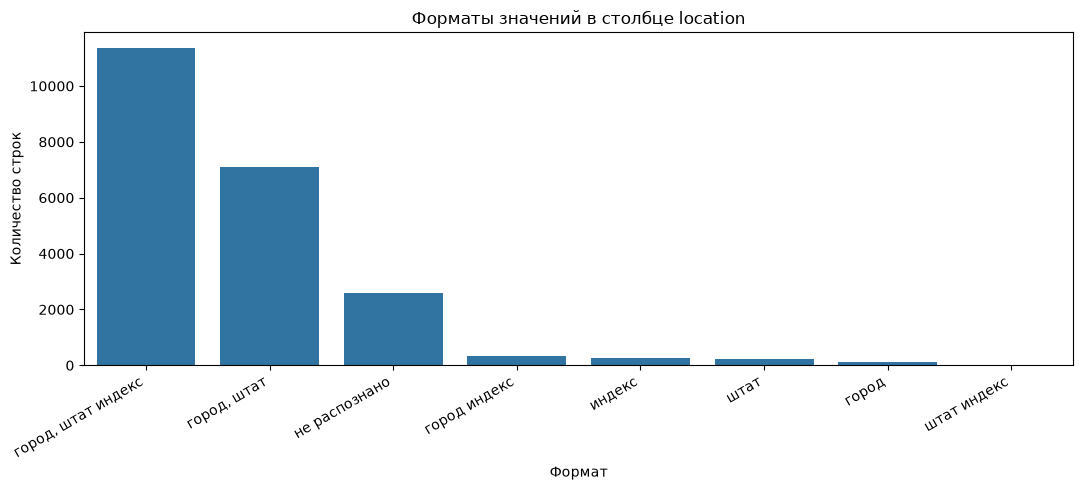

format
город, штат индекс    11353
город, штат            7114
не распознано          2587
город индекс            327
индекс                  254
штат                    230
город                   114
штат индекс              21
Name: count, dtype: int64

In [27]:
# Классификация по первому совпадению: порядок столбцов matches = приоритет паттернов.
# idxmax возвращает имя первого столбца с True; строкам без совпадений ставим "не распознано".
matches = pd.DataFrame({
    name: df["location"].str.fullmatch(pat).fillna(False)
    for name, pat in location_patterns.items()
})
recognized = matches.any(axis=1)
df["location_format"] = matches.idxmax(axis=1).where(recognized, "не распознано")
format_counts = df["location_format"].value_counts().rename("count")
format_counts.index.name = "format"
assert format_counts.sum() == len(df), "каждая строка должна получить ровно один формат"

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=format_counts.reset_index(), x="format", y="count", ax=ax)
ax.set_title("Форматы значений в столбце location")
ax.set_xlabel("Формат")
ax.set_ylabel("Количество строк")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
format_counts

**Вывод по заданию 1.1:** чаще всего встречаются форматы «город, штат индекс» (11353 строки, 51.6%) и «город, штат» (7114, 32.3%) — вместе 84% столбца. Реже — «город индекс» (327), «индекс» (254), «штат» (230), «город» (114), «штат индекс» (21). В 2587 строках (11.8%) формат определить не удалось: это обрывки описаний вакансий, контактные данные, телефоны и прочие значения, не являющиеся местоположением. Они вынесены в отложенную выборку для разбора в задании 1.3.

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [28]:
# Извлечение полей: именованные группы (?P<name>...) — str.extract вернёт столбец на каждую группу.
# Порядок и приоритеты те же, что в location_patterns.
location_extract_patterns = {
    "город, штат индекс": r"^(?P<city>[A-Za-z.]+(?: [A-Za-z.]+)*),\s*(?P<state>[A-Z]{2})\s+(?P<zip>\d{5}(?:-\d{4})?)$",
    "город, штат": r"^(?P<city>[A-Za-z.]+(?: [A-Za-z.]+)*),\s*(?P<state>[A-Z]{2})\s*$",
    "штат индекс": r"^(?P<state>[A-Z]{2})\s+(?P<zip>\d{5}(?:-\d{4})?)$",
    "город индекс": r"^(?P<city>[A-Za-z.]+(?: [A-Za-z.]+)*)\s+(?P<zip>\d{5}(?:-\d{4})?)$",
    "индекс": r"^(?P<zip>\d{5}(?:-\d{4})?)$",
    "штат": r"^(?P<state>[A-Z]{2})$",
    "город": r"^(?P<city>[A-Za-z.]+)$",
}

parts = [
    df.loc[df["location_format"] == fmt, "location"].str.extract(pat)
    for fmt, pat in location_extract_patterns.items()
]
location_split = pd.concat(parts).reindex(df.index).reindex(columns=["city", "state", "zip"])
df[["city", "state", "zip"]] = location_split

# Отложенная выборка: формат определить не удалось
location_deferred_df = df[df["location_format"] == "не распознано"].copy()

print(f"Разложено на city/state/zip: {len(df) - len(location_deferred_df)} строк")
print(f"Отложено для разбора в задании 1.3: {len(location_deferred_df)} строк")
df[["location", "location_format", "city", "state", "zip"]].sample(10, random_state=42)

Разложено на city/state/zip: 19413 строк
Отложено для разбора в задании 1.3: 2587 строк


,location,location_format,city,state,zip
13035,"Santa Cruz, CA 95060","город, штат индекс",Santa Cruz,CA,95060
3115,"Sunset Point, FL 33765","город, штат индекс",Sunset Point,FL,33765
8732,"Atlanta, GA 30301","город, штат индекс",Atlanta,GA,30301
7591,"Knoxville, TN 37923","город, штат индекс",Knoxville,TN,37923
221,"Knoxville, TN","город, штат",Knoxville,TN,NaN
17295,"Dallas, TX","город, штат",Dallas,TX,NaN
5857,"Plymouth, MI 48170","город, штат индекс",Plymouth,MI,48170
12608,"Camphill, PA","город, штат",Camphill,PA,NaN
3463,"Astoria, NY","город, штат",Astoria,NY,NaN
6478,"Richmond, MO 64085","город, штат индекс",Richmond,MO,64085


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [29]:
location_deferred_df["location"].sample(30, random_state=1).tolist()

['Service Order DispatcherProxy Personnel is actively seeking and experienced administrative professional to assist with property management responsibilities within a federal building. We are looking for an individual with exceptional organizational skills to perform clerical tasks such as these within a property management organization:Handle over 400 mechanical/custodial service requests a month.Reconcile and coordinate contractor payments and administer regulatory requirements.Act as a liaison between various agencies, property management and general contractors.Create documents and databases with Microsoft Suite, including Access.Answer phones and offer assistance with troubleshooting routine issues.Prepare business calendars; assist with scheduling of meetings, conferences and conference room.Utilize excellent writing skills in order to compose memos, instructions and other communications. Provide administrative support for office personnel and clientsMaintain, organize, and archi

In [32]:
# Извлечение полей из отложенной выборки.
# В отличие от задания 1.2, здесь ищем совпадения ВНУТРИ строки (без якорей ^...$).
deferred_idx = location_deferred_df.index
loc = df.loc[deferred_idx, "location"]

# Правило 1: города с дефисом ("Winston-Salem, NC 27104"), полный формат
CITY_H = r"[A-Za-z.]+(?:-[A-Za-z.]+)*(?: [A-Za-z.]+(?:-[A-Za-z.]+)*)*"
p_hyphen = rf"^(?P<city>{CITY_H}),\s*(?P<state>[A-Z]{{2}})(?:\s+(?P<zip>\d{{5}}(?:-\d{{4}})?))?$"
# Правило 2: "Job in <город> <индекс>"
p_jobin = r"Job in (?P<city>[A-Za-z.-]+(?: [A-Za-z.-]+)*?) (?P<zip>\d{5})"
# Правило 3: поиск ", <штат> [индекс]" в любом месте строки (адреса, описания)
p_statezip = r",\s*(?P<state>[A-Z]{2})\b(?:\s+(?P<zip>\d{5}(?:-\d{4})?))?"
# Правило 4: город по словарю уже извлечённых городов (длинные названия раньше коротких)
known_cities = df["city"].dropna().unique()
city_alt = "|".join(sorted(map(re.escape, known_cities), key=len, reverse=True))
p_city_dict = rf"(?P<city>{city_alt})"

r1 = loc.str.extract(p_hyphen)
r2 = loc.str.extract(p_jobin)
r3 = loc.str.extract(p_statezip)
r4 = loc.str.extract(p_city_dict)

location_rescued = r1.fillna(r2).fillna(r3)
location_rescued["city"] = location_rescued["city"].fillna(r4["city"])
df.loc[deferred_idx, ["city", "state", "zip"]] = location_rescued

rescued_mask = location_rescued.notna().any(axis=1)
print(f"Извлечено хоть одно поле: {rescued_mask.sum()} из {len(loc)} отложенных строк")
print(f"Осталось полностью пустых (мусор без признаков местоположения): {(~rescued_mask).sum()}")
pd.concat([loc.str.slice(0, 60).rename("location (первые 60 символов)"), location_rescued], axis=1)[rescued_mask].head(8)

Извлечено хоть одно поле: 1640 из 2587 отложенных строк
Осталось полностью пустых (мусор без признаков местоположения): 947


,location (первые 60 символов),city,state,zip
2,DePuy Synthes Companies is a member of Johnson...,Raynham,MA,NaN
45,Respiratory Therapist PRN Nights - Kindred Hos...,Houston,NaN,NaN
72,"""Statewide"", CO",NaN,CO,NaN
105,Registered Nurse ICU Full Time Days - Kindred ...,Houston,NaN,NaN
115,Experienced Registered Nurse-Critical Care/ICU...,Houston,NaN,NaN
135,"Bafb, Aurora 80011",Aurora,NaN,NaN
138,Registered Nurse ICU Full Time Nights - Kindre...,Houston,NaN,NaN
188,"Location: Spokane, WAOverview: Responsible fo...",Spokane,NaN,NaN


**Вывод по заданию 1.3:** отложенные 2587 строк разделились на категории:

- города с дефисом («Winston-Salem, NC 27104») — 13 строк, полный формат, извлечены все три поля (дефис добавлен в класс символов города);
- записи вида «Job in город индекс» — 47 строк, извлечены город и индекс; штат указан полным именем («Virginia», «Utah»), а не кодом, и оставлен пустым;
- адреса и описания вакансий, внутри которых есть «, штат [индекс]» — 914 строк, штат и индекс найдены поиском без якорей (например, «Address 221 S Roop StreetSusanville, CA 96130»);
- город дополнительно восстановлен по словарю городов, извлечённых в задании 1.2 (1595 строк) — в склеенных адресах («...RoadLas Vegas, NV») это единственный надёжный способ отделить город от улицы.

Итого хотя бы одно поле извлечено из 1640 отложенных строк; 947 строк — контакты, телефоны и обрывки описаний без признаков местоположения, они оставлены пустыми. Суммарно по датасету поля city/state/zip заполнены хотя бы частично в 21053 строках из 22000.

**Ограничения:** город из словаря — первое вхождение названия в строке, в длинных описаниях оно может отличаться от фактического места работы; полные имена штатов не нормализованы в коды.

### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

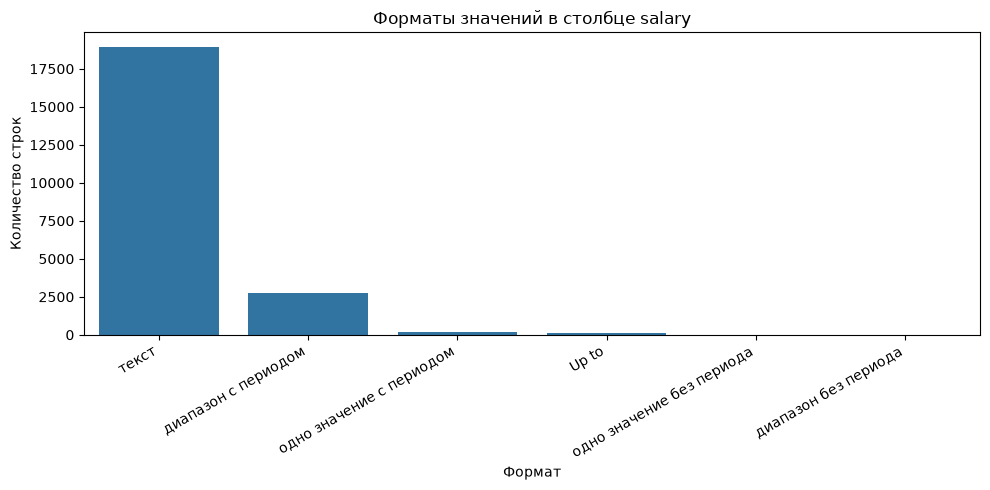

текст                        18949
диапазон с периодом           2748
одно значение с периодом       172
Up to                          101
одно значение без периода       17
диапазон без периода            13
Name: count, dtype: int64

In [34]:
# Нормализуем пробелы и классифицируем форматы (приоритет: первое совпадение, как в location)
salary_norm = df["salary"].str.replace(r"\s+", " ", regex=True).str.strip()
NUM = r"\d[\d,]*(?:\.\d+)?"
salary_patterns = {
    "диапазон": rf"^\$?\s*(?P<min>{NUM})\s*-\s*\$?\s*(?P<max>{NUM})\s*\$?\s*(?:/\s*(?P<period>hour|year|month|week))?",
    "одно значение": rf"^\$?\s*(?P<min>{NUM})\s*\+?\s*\$?\s*(?:/\s*(?P<period>hour|year|month|week))?",
    "Up to": rf"^Up to\s*\$?\s*(?P<max>{NUM})",
}
sal_parts = {name: salary_norm.str.extract(pat) for name, pat in salary_patterns.items()}

sal_format = pd.Series("текст", index=df.index)
for name in reversed(list(salary_patterns)):
    sal_format[sal_parts[name].notna().any(axis=1)] = name

sal_period = sal_parts["диапазон"]["period"].fillna(sal_parts["одно значение"]["period"])
sal_format_detail = sal_format + np.where(
    sal_format.isin(["диапазон", "одно значение"]),
    np.where(sal_period.notna(), " с периодом", " без периода"),
    "",
)
salary_format_counts = sal_format_detail.value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=salary_format_counts.index, y=salary_format_counts.values, ax=ax)
ax.set_title("Форматы значений в столбце salary")
ax.set_xlabel("Формат")
ax.set_ylabel("Количество строк")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
salary_format_counts

**Вывод по заданию 2.1:** среди 3446 заполненных ячеек salary доминирует формат «диапазон с периодом» — 2748 (79.7%); далее «одно значение с периодом» — 172, «Up to» — 101, «одно значение без периода» — 17, «диапазон без периода» — 13. Произвольный текст («Commensurate with Experience», «Excellent Pay and Incentives» и т.п.) — 395 записей; ещё 18554 ячейки пусты (всего «текст/пусто» 18949). Знак доллара может стоять до или после суммы и отсутствовать; пробелы произвольны; периоды — hour, year, month, week.

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

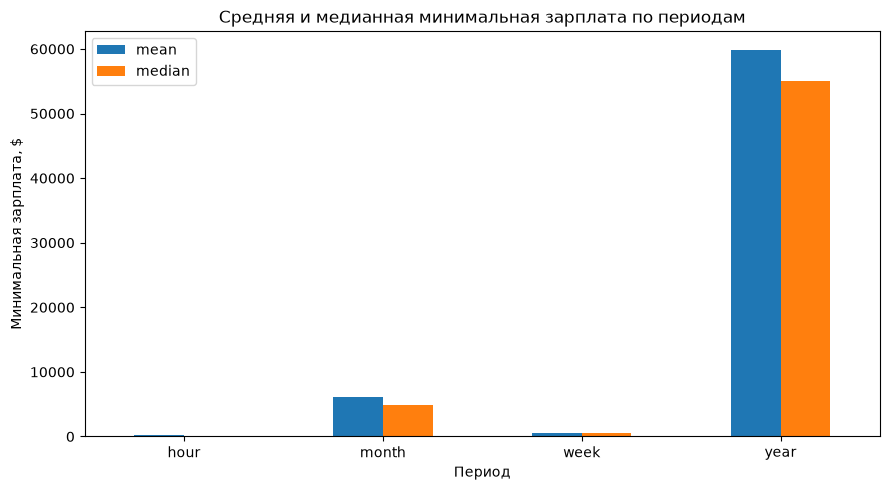

,mean,median
salary_period,,
hour,187.610657,15.13
month,6048.408824,4905.22
week,593.666667,600.00
year,59789.876160,55000.00


In [35]:
# Разбор на min / max / period. Одиночная сумма -> min; "Up to" — верхняя граница, поэтому max.
salary_extracted = sal_parts["диапазон"].fillna(sal_parts["одно значение"])
salary_extracted["max"] = salary_extracted["max"].fillna(sal_parts["Up to"]["max"])

df["salary_min"] = salary_extracted["min"].str.replace(",", "", regex=False).astype(float)
df["salary_max"] = salary_extracted["max"].str.replace(",", "", regex=False).astype(float)
df["salary_period"] = sal_period

salary_stats = df.groupby("salary_period")["salary_min"].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(9, 5))
salary_stats.plot(kind="bar", ax=ax)
ax.set_title("Средняя и медианная минимальная зарплата по периодам")
ax.set_xlabel("Период")
ax.set_ylabel("Минимальная зарплата, $")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
salary_stats

**Вывод по заданию 2.2:** зарплаты разложены на ```salary_min```, ```salary_max``` (float) и ```salary_period```. Одиночная сумма трактуется как минимальная; для формата «Up to» сумма является верхней границей и помещена в ```salary_max``` (осознанное уточнение правила задания).

Среднее и медиана минимальной зарплаты по периодам: hour — 187.6 / 15.13, month — 6048 / 4905, week — 594 / 600, year — 59790 / 55000. Огромный разрыв среднего и медианы у hour (максимум 100000 $/час — годовая зарплата, ошибочно указанная как почасовая) показывает, что среднее чувствительно к выбросам, а медиана — робастная оценка. Периоды различаются на порядки, поэтому сравнивать суммы без учёта периода нельзя.

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

Сумм без периода: 131
Период восстановлен: 130
hour     65
year     50
week     14
month     1
Осталось без периода (неоднозначно): 1


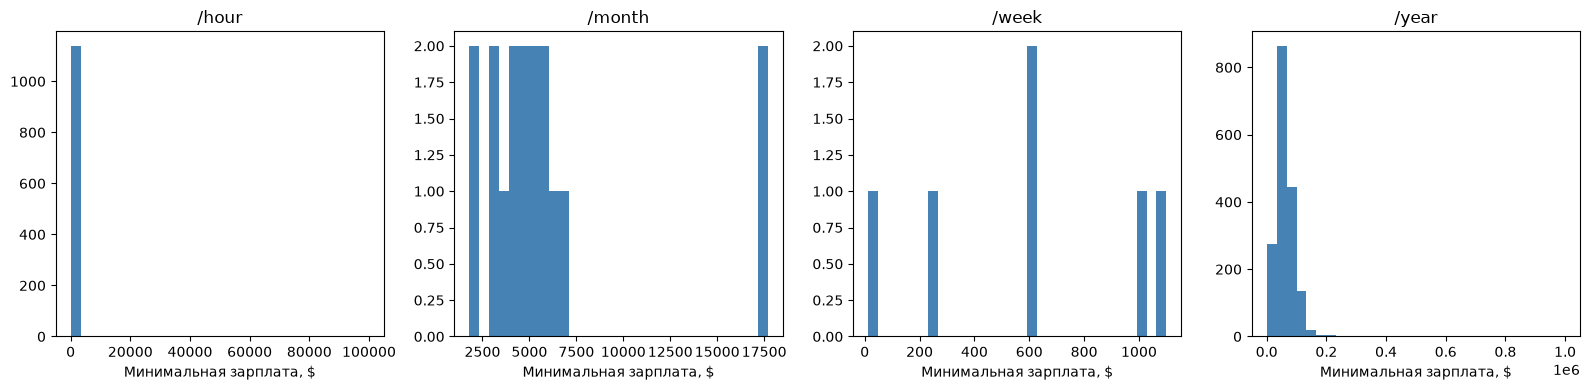

In [37]:
# 1. Разброс минимальной зарплаты по периодам и гистограммы
period_stats = df.groupby("salary_period")["salary_min"].describe()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (period, group) in zip(axes, df.groupby("salary_period")):
    ax.hist(group["salary_min"].dropna(), bins=30, color="steelblue")
    ax.set_title(f"/{period}")
    ax.set_xlabel("Минимальная зарплата, $")
plt.tight_layout()
plt.show()
period_stats

# 2. Восстановление отсутствующего периода.
# Выбросы отсекаем правилом 1.5*IQR; диапазон и среднее считаем только по инлаерам.
inlier_stats = {}
for period, group in df.groupby("salary_period"):
    x = group["salary_min"].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    fence_lo, fence_hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    x_in = x[(x >= fence_lo) & (x <= fence_hi)]
    inlier_stats[period] = (x_in.min(), x_in.max(), x_in.mean())

no_period = df["salary_period"].isna() & (df["salary_min"].notna() | df["salary_max"].notna())
amounts = df.loc[no_period, "salary_min"].fillna(df.loc[no_period, "salary_max"])
in_range = pd.DataFrame({p: amounts.between(lo, hi) for p, (lo, hi, _) in inlier_stats.items()})
dist = pd.DataFrame({p: (amounts - mean).abs() for p, (_, _, mean) in inlier_stats.items()})

imputed = pd.Series(index=amounts.index, dtype=object)
# сумма попала ровно в один диапазон — период однозначен
one_candidate = in_range.sum(axis=1) == 1
imputed[one_candidate] = in_range[one_candidate].idxmax(axis=1)
# сумма попала в несколько диапазонов — выбираем ближайший к среднему, если он единственный
many = in_range.sum(axis=1) > 1
d = dist[many].where(in_range[many])
nearest = d.idxmin(axis=1)
unique_nearest = d.eq(d.min(axis=1), axis=0).sum(axis=1) == 1
imputed[many] = nearest[unique_nearest]

df.loc[no_period, "salary_period"] = imputed
print(f"Сумм без периода: {no_period.sum()}")
print(f"Период восстановлен: {imputed.notna().sum()}")
print(imputed.value_counts().to_string())
print(f"Осталось без периода (неоднозначно): {imputed.isna().sum()}")

**Вывод по заданию 2.3:** робастные диапазоны минимальной зарплаты (инлаеры по правилу 1.5·IQR): hour — примерно 0–40 $/час (медиана 15), week — 12–1100 (медиана 600, всего 6 записей), month — 1800–9500 (медиана 4905), year — 0–127500 (медиана 55000). Гистограммы подтверждают результаты задания 2.2: hour сосредоточен в 10–30, year — в 40–100 тыс., при этом видны единичные выбросы (0 и 1 000 000), которые и искажали среднее в 2.2.

Из 131 суммы без периода период восстановлен для 130: hour — 65, year — 50, week — 14, month — 1. Одна сумма осталась без периода как неоднозначная. Метод: если сумма попадает ровно в один робастный диапазон — период однозначен; если в несколько — выбирается ближайший к среднему инлаеров, и только если он единственный; иначе период не назначается.

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

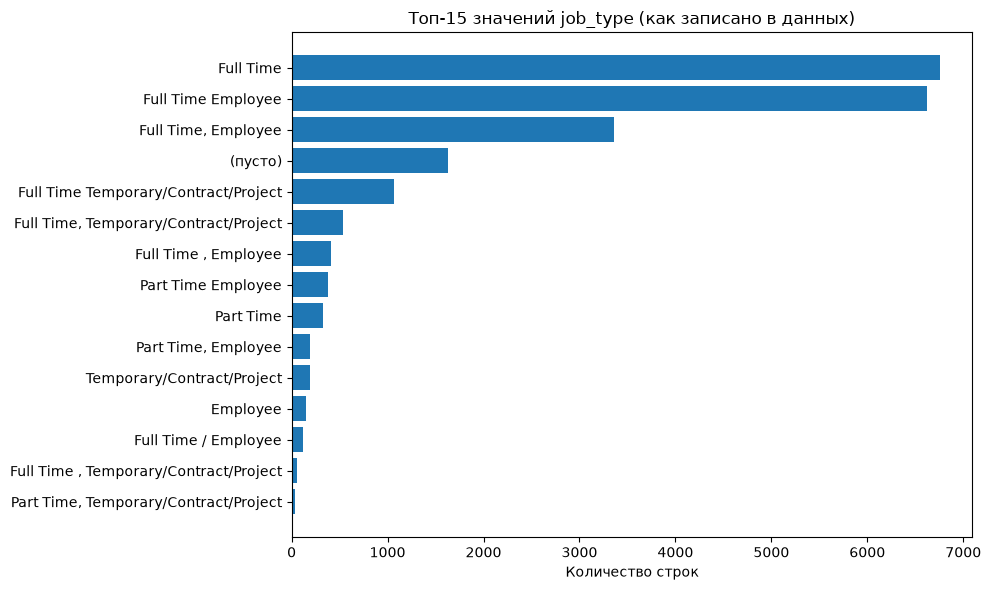

job_type
Full Time                                        6757
Full Time Employee                               6617
Full Time, Employee                              3360
NaN                                              1628
Full Time Temporary/Contract/Project             1062
Full Time, Temporary/Contract/Project             533
Full Time , Employee                              406
Part Time Employee                                382
Part Time                                         329
Part Time, Employee                               196
Temporary/Contract/Project                        193
Employee                                          147
Full Time / Employee                              121
Full Time , Temporary/Contract/Project             56
Part Time, Temporary/Contract/Project              34
Per Diem, Employee                                 29
Per Diem                                           22
Job Type Full Time Employee                        19
Part Time Seasonal 

In [39]:
# Какие форматы значений встречаются в job_type
job_type_counts = df["job_type"].value_counts(dropna=False)
top = job_type_counts.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
labels = ["(пусто)" if pd.isna(v) else str(v) for v in top.index]
ax.barh(labels[::-1], top.values[::-1])
ax.set_title("Топ-15 значений job_type (как записано в данных)")
ax.set_xlabel("Количество строк")
plt.tight_layout()
plt.show()
job_type_counts

**Вывод по форматам job_type:** 39 уникальных написаний, но семантически это решётка «полнота занятости» (Full Time / Part Time / Per Diem) × «тип занятости» (Employee / Intern / Seasonal / Temporary/Contract/Project). Разнобой создают: разделители (пробел, запятая, слеш, их комбинации), префикс «Job Type», хвостовые пробелы, неполные записи (только полнота или только тип) и 1628 пустых ячеек. Перед анализом значения необходимо нормализовать.

Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [40]:
# Приведение к единому формату "Полнота, Тип":
# убираем префикс "Job Type", лишние пробелы и ">", унифицируем разделители.
# Слеши внутри "Temporary/Contract/Project" защищаем от замены на запятые.
def normalize_job_type(value):
    if pd.isna(value):
        return value
    s = re.sub(r"^Job Type\s*", "", value.strip())
    s = s.replace(">", "")
    s = s.replace("Temporary/Contract/Project", "TemporaryContractProject")
    s = re.sub(r"\s*[,/]\s*", ", ", s)
    s = re.sub(r"\s+", " ", s).strip(" ,")
    s = re.sub(r"^(Full Time|Part Time|Per Diem) (Employee|Intern|Seasonal|TemporaryContractProject)$", r"\1, \2", s)
    return s.replace("TemporaryContractProject", "Temporary/Contract/Project")

df["job_type_normalized"] = df["job_type"].map(normalize_job_type)
print("Уникальных значений до:", df["job_type"].nunique(), "→ после:", df["job_type_normalized"].nunique())
df["job_type_normalized"].value_counts(dropna=False)

Уникальных значений до: 39 → после: 15


job_type_normalized
Full Time, Employee                      10538
Full Time                                 6773
Full Time, Temporary/Contract/Project     1654
NaN                                       1628
Part Time, Employee                        586
Part Time                                  330
Temporary/Contract/Project                 193
Employee                                   148
Part Time, Temporary/Contract/Project       57
Per Diem, Employee                          41
Per Diem                                    22
Part Time, Seasonal                         17
Full Time, Intern                            5
Per Diem, Temporary/Contract/Project         4
Part Time, Intern                            3
Exempt                                       1
Name: count, dtype: int64

**Вывод (нормализация):** число уникальных написаний сократилось с 39 до 15. Все значения приведены к единому формату «Полнота, Тип»: удалён префикс «Job Type», лишние пробелы и символ «>», разделители (пробел, запятая, слеш) унифицированы. Слеши внутри «Temporary/Contract/Project» защищены от замены, чтобы не разрушить составное значение.

Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

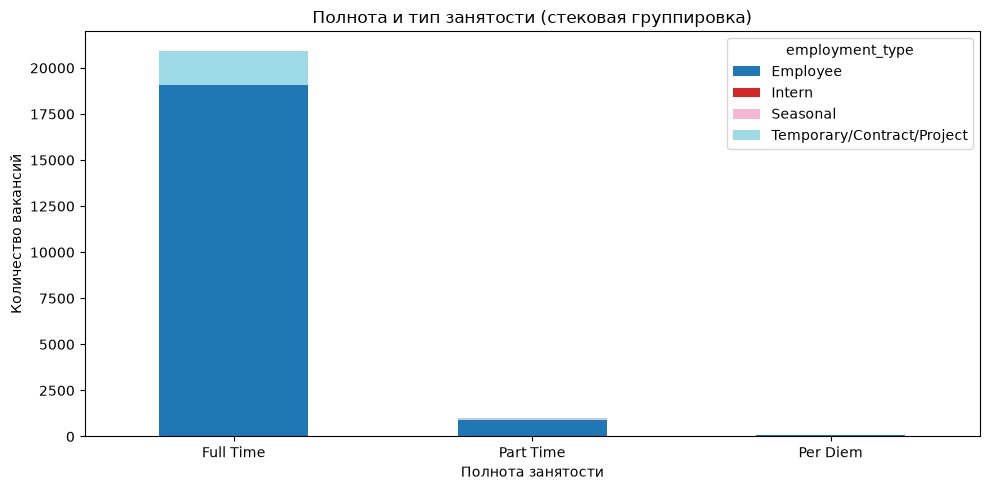

employment_type,Employee,Intern,Seasonal,Temporary/Contract/Project
job_fullness,,,,
Full Time,19088,5,0,1847
Part Time,916,3,17,57
Per Diem,63,0,0,4


In [41]:
# Разделение на полноту и тип занятости + значения по умолчанию для неполных записей.
# Кроме Employee/Intern в данных реально встречаются Seasonal и Temporary/Contract/Project — сохраняем их.
jt = df["job_type_normalized"]
df["job_fullness"] = jt.str.extract(r"^(Full Time|Part Time|Per Diem)\b")[0].fillna("Full Time")
df["employment_type"] = jt.str.extract(r"\b(Employee|Intern|Seasonal|Temporary/Contract/Project)\b")[0].fillna("Employee")

ct = pd.crosstab(df["job_fullness"], df["employment_type"])
fig, ax = plt.subplots(figsize=(10, 5))
ct.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
ax.set_title("Полнота и тип занятости (стековая группировка)")
ax.set_xlabel("Полнота занятости")
ax.set_ylabel("Количество вакансий")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
ct

**Вывод по заданию 3 (разделение):** столбец разложен на ```job_fullness``` (полнота) и ```employment_type``` (тип). Отсутствующая полнота заполнена значением ```Full Time```, отсутствующий тип — ```Employee``` (включая 1628 строк с пустым ```job_type```); единичное значение «Exempt» также отнесено к значениям по умолчанию как шум. Помимо заявленных в задании ```Employee```/```Intern``` сохранены реально встречающиеся в данных ```Seasonal``` и ```Temporary/Contract/Project``` — иначе эта информация была бы потеряна.

Итог: Full Time — 20940 вакансий (95.2%), Part Time — 993 (4.5%), Per Diem — 67 (0.3%); по типу: Employee — 20067 (91.2%), Temporary/Contract/Project — 1908 (8.7%), Seasonal — 17, Intern — 8. Выборка почти полностью состоит из вакансий полной занятости для штатных сотрудников.

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.